# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [2]:
ROLL_NO = 1024170330
NAME = "Vanshika Sohal"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170330   Name: Vanshika Sohal   Fingerprint: 6EC110CF   Tickets: 12

Ticket_ID                                                                               Ticket_Text
      T01         I reinstalled the lms when connected to campus Wi-Fi. I have tried several times!
      T02          Laptop is running slowly while uploading the file. It works on another computer.
      T03 I cannot access the printer before the assignment deadline. It works on another computer.
      T04         Wi-Fi has stopped syncing after resetting my password. Is there another solution?
      T05                                                     I need Windows 11 by 5.30 p.m. today.
      T06                                                             Why isn't the portal opening?
      T07                                                 The VPN keeps disconnecting. Please help.
      T08            I couldn't connect to the printer since yesterday. I have tried several times!
      T09     

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
import pandas as pd
results = {}
rows = []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    r = process_ticket(text)
    results[tid] = r
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(r["sentences"]),
        "Tokens": len(r["tokens"]),
        "Punct": len(r["punct"]),
        "Stopwords": len(r["stops"]),
        "Unique_Tokens": len(set(r["tokens"])),
        "Final_Tokens": len(r["final"]),
    })

tbl = pd.DataFrame(rows)

total = tbl.drop(columns="Ticket_ID").sum()
total["Ticket_ID"] = "TOTAL"
tbl = pd.concat([tbl, total.to_frame().T], ignore_index=True)
print(tbl.to_string(index=False))

# Selected ticket
sel = FOCUS[0]
r = results[sel]
print(f"\nSelected ticket: {sel}")
print("Text      :", df.loc[df.Ticket_ID == sel, "Ticket_Text"].values[0])
print("Tokens    :", r["tokens"])
print("Punct     :", r["punct"])
print("Stopwords :", r["stops"])
print("Final     :", r["final"])

Ticket_ID Sentences Tokens Punct Stopwords Unique_Tokens Final_Tokens
      T01         2     16     2         6            15            8
      T02         2     15     2         5            14            8
      T03         2     17     2         8            15            7
      T04         2     14     2         5            14            7
      T05         1      9     1         2             9            6
      T06         1      7     1         3             7            3
      T07         2      8     2         1             7            5
      T08         2     16     2         5            15            9
      T09         2     14     2         4            12            8
      T10         1      9     2         1             9            6
      T11         1      9     1         3             9            5
      T12         2     12     2         5            10            5
    TOTAL        20    146    21        48           136           77

Selected ticket: T0

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

**Ans** : In my dataset, the non-word final tokens are n't, p.m., lms, and fragments of phone numbers and decimals (+91, 98765, 43210, 0175-239-3201, 5.30).

n't comes from T06 (isn’t), T08 (couldn’t) and T10 (didn’t). word_tokenize (the Treebank tokenizer) splits contractions: isn’t → is + n't, couldn’t → could + n't, didn’t → did + n't. The words is, could and did are in NLTK’s stopword list, so they were removed. n't is not in that list (the list contains clipped forms like isn, couldn, didn), and it is not punctuation either, so it survives into the final tokens.

p.m. (T05) is an abbreviation. is_punct does not treat it as punctuation because it contains letters. The phone number (T11) and decimal (T05) fragments come straight out of the tokenizer and are not stopwords or punctuation, so they also stay in the final tokens. lms is a lowercased acronym that passes through the same way.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
import re
from nltk.tokenize import sent_tokenize

PATTERNS = {
    "long_words (>5 letters)": r"\b[A-Za-z]{6,}\b",
    "numbers":                 r"\b\d+(?:[.,]\d+)*\b",      # 95.5, 2.0.1, 1,250 stay whole
    "capitalized":             r"\b[A-Z][a-z]+\b",
    "vowel_start":             r"\b[aeiou][a-z]*\b",        # used with re.I
}


EMAIL = r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b"
URL   = r"(?:https?://|www\.)[\w\-./~%?=&#]*[\w/]"          # last char can't be '.'
PHONE = r"(?:\+\d{1,3}[ -]?\d{5}[ -]?\d{5}|\b\d{4}-\d{3}-\d{4}\b)"

def extract(text):
    out = {}
    for name, pat in PATTERNS.items():
        flags = re.I if name == "vowel_start" else 0
        out[name] = re.findall(pat, text, flags)
    return out

def mask(text):
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(URL,   "<URL>",   text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text

for line in TEST_LINES:
    print("RAW   :", line)
    for k, v in extract(line).items():
        print(f"  {k:26}", v)
    print("MASKED:", mask(line), "\n")

for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    print(tid, "|", text)
    for k, v in extract(text).items():
        print(f"  {k:26}", v)
    print("  MASKED:", mask(text), "\n")

start_cap, other_cap = [], []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    for sent in sent_tokenize(text):
        first = re.search(r"[A-Za-z]", sent).start()
        for m in re.finditer(PATTERNS["capitalized"], sent):
            (start_cap if m.start() == first else other_cap).append((tid, m.group()))

total = len(start_cap) + len(other_cap)
print(f"Capitalized total: {total}")
print(f"Only due to sentence start: {len(start_cap)} -> {start_cap}")
print(f"Genuinely capitalized     : {len(other_cap)} -> {other_cap}")

RAW   : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  long_words (>5 letters)    ['helpdesk', 'thapar', 'thapar', 'thapar']
  numbers                    []
  capitalized                ['Mail']
  vowel_start                ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
MASKED: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>. 

RAW   : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  long_words (>5 letters)    ['Version']
  numbers                    ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
  capitalized                ['Call', 'Version', 'Rs']
  vowel_start                ['or', 'is']
MASKED: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250. 

RAW   : The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  long_words (>5 letters)    []
  numbers     

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

**Ans** : 14 of my 18 capitalized words (about 78%) are capitalized only because they begin a sentence: Laptop, It, It, Wi, Is, Why, The, Please, Student, It, Re, Call, The, The. Only 4 are capitalized for another reason: Wi and Fi in T01, Fi in T04 (all from the proper noun Wi-Fi), and Windows in T05, a product name. So the capitalized-word pattern mostly detects sentence position, not proper nouns. Lowercasing would erase that signal, so a better extractor should ignore the first word of each sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize
from collections import Counter

PATTERN = r"""(?x)
    [\w.+-]+@[\w-]+(?:\.[\w-]+)+                              # email
  | (?:https?://|www\.)[\w\-./~%?=&\#]*[\w/]                  # URL
  | \+\d{1,3}[ -]?\d{5}[ -]?\d{5} | \d{4}-\d{3}-\d{4}         # phone
  | \d+(?:[.,]\d+)*(?!\w)                                     # int / decimal / version / 1,250
  | (?:[A-Za-z]\.){2,}                                        # abbreviations (p.m.)
  | \w+(?:[-']\w+)*                                           # words, contractions, hyphenated
  | \.{3} | [^\w\s]                                           # ellipsis / single punctuation
"""

_tok = RegexpTokenizer(PATTERN)

def my_tokenize(text):
    return _tok.tokenize(text)

def diff(a, b):
    ca, cb = Counter(a), Counter(b)
    return list((ca - cb).elements()), list((cb - ca).elements())

def compare(label, text):
    mine, nltk_t = my_tokenize(text), word_tokenize(text)
    only_mine, only_nltk = diff(mine, nltk_t)
    print(f"[{label}] {text}")
    print("  mine :", mine)
    print("  nltk :", nltk_t)
    print("  only in mine :", only_mine)
    print("  only in nltk :", only_nltk, "\n")

for i, line in enumerate(TEST_LINES, 1):
    compare(f"TEST{i}", line)

for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    compare(tid, text)

[TEST1] Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  mine : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  nltk : ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  only in mine : ['it.helpdesk@thapar.edu', 'a.b-c@dept.univ.ac.in', 'https://lms.thapar.edu/help']
  only in nltk : ['it.helpdesk', '@', '@', 'thapar.edu', 'a.b-c', 'dept.univ.ac.in', 'https', ':', '//lms.thapar.edu/help'] 

[TEST2] Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  mine : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
  nltk : ['Call', '+91', '98765', '43210', ',', '+91-

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

**Ans** : 5 of my 12 tickets (about 42%) are tokenized differently: T03, T06, T08, T10 and T11. The other 7 (T01, T02, T04, T05, T07, T09, T12) come out identical. The differences come from contractions (T06, T08, T10), “cannot” (T03) and a space-separated phone number (T11).

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:
import pandas as pd
from nltk import pos_tag
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

final_all = [t for r in results.values() for t in r["final"]]
uniq = sorted(set(final_all))

pos_map = {}
for r in results.values():
    for w, tag in pos_tag(r["tokens"]):
        pos_map.setdefault(w, tag)

def wn_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB,
            "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

porter = PorterStemmer()
lanc   = LancasterStemmer()
regex  = RegexpStemmer("ing$", min=4)
lemma  = WordNetLemmatizer()

rows = []
for w in uniq:
    tag = pos_map.get(w, "NN")
    rows.append({
        "Word": w,
        "POS": tag,
        "Porter": porter.stem(w),
        "Lancaster": lanc.stem(w),
        "Regexp(ing$)": regex.stem(w),
        "WN_Lemma": lemma.lemmatize(w, wn_pos(tag)),
    })

cmp_df = pd.DataFrame(rows)

cols = ["Porter", "Lancaster", "Regexp(ing$)", "WN_Lemma"]
diff_df = cmp_df[cmp_df[cols].nunique(axis=1) > 1]

print("Unique final tokens:", len(uniq))
print("Words with differing outputs:", len(diff_df))
print(diff_df.to_string(index=False))

ing_words = [w for w in uniq if w.endswith("ing")]
print("\n'ing' words in my data:", ing_words)

Unique final tokens: 60
Words with differing outputs: 38
         Word POS    Porter     Lancaster Regexp(ing$)      WN_Lemma
      another  DT     anoth         anoth      another       another
   assignment  JJ    assign        assign   assignment    assignment
         call  VB      call           cal         call          call
       campus  VB     campu          camp       campus        campus
     computer  NN    comput        comput     computer      computer
    connected VBN   connect       connect    connected       connect
     deadline  NN   deadlin       deadlin     deadline      deadline
        fails VBZ      fail          fail        fails          fail
         file  NN      file           fil         file          file
        keeps NNS      keep          keep        keeps          keep
       latest JJS    latest        latest       latest          late
          lms  NN        lm           lms          lms            lm
         need VBP      need           nee     

**Observe:** Give one over-stemming and one under-stemming example from your table.

**Ans** : Over-stemming (two different words collapsed into one stem): Lancaster stems solution to solv, which merges it with solve/solvable. It also turns printer into print and student into stud, so different words end up sharing a stem. Porter does it too: several becomes sever, the same stem as severe, which means something completely different.
Under-stemming (related forms that should share a stem but don’t): re-installing stays as re-installing under Lancaster, while Porter gives re-instal, and reinstalled gives reinstal under both. So reinstalled and re-installing end up with different stems (reinstal vs re-instal) even though they are the same verb. Also, the Regexp stemmer leaves connected, stopped, worked and tried unchanged, so they do not match connect, stop, work and try.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

             Set  Total  Unique    TTR
 S1 (all tokens)    146      88 0.6027
   S2 (no punct)    125      84 0.6720
      S3 (final)     77      60 0.7792
S4 (S3 + Porter)     77      57 0.7403

Top 10 S1: [('.', 15), ('the', 10), ('i', 6), ('is', 4), ('!', 3), ('it', 3), ('on', 3), ('another', 3), ("n't", 3), ('yesterday', 3)]
Top 10 S3: [('another', 3), ("n't", 3), ('yesterday', 3), ('wi-fi', 2), ('tried', 2), ('several', 2), ('times', 2), ('running', 2), ('slowly', 2), ('works', 2)]


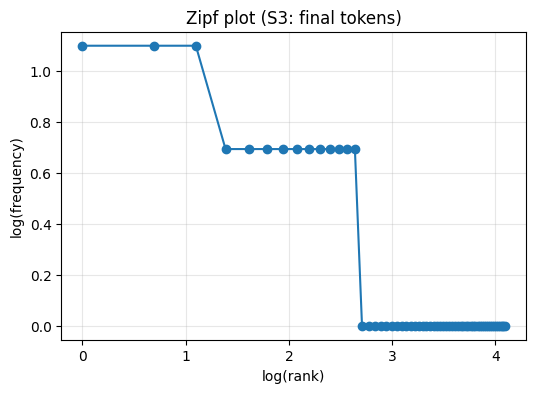


Top 5 bigrams S1: [(('.', 'it'), 3), (('.', 'i'), 2), (('i', 'have'), 2), (('have', 'tried'), 2), (('tried', 'several'), 2)]
Top 5 bigrams S3: [(('tried', 'several'), 2), (('several', 'times'), 2), (('running', 'slowly'), 2), (('works', 'another'), 2), (('another', 'computer'), 2)]


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk import bigrams
from nltk.stem import PorterStemmer

porter = PorterStemmer()

# Per-ticket lists (keeps bigrams from crossing ticket boundaries)
S1_t = [r["tokens"] for r in results.values()]
S2_t = [[t for t in r["tokens"] if not is_punct(t)] for r in results.values()]
S3_t = [r["final"] for r in results.values()]
S4_t = [[porter.stem(t) for t in r["final"]] for r in results.values()]

sets = {"S1 (all tokens)": S1_t, "S2 (no punct)": S2_t,
        "S3 (final)": S3_t, "S4 (S3 + Porter)": S4_t}

rows = []
for name, lists in sets.items():
    flat = [t for l in lists for t in l]
    rows.append({"Set": name, "Total": len(flat), "Unique": len(set(flat)),
                 "TTR": round(len(set(flat)) / len(flat), 4)})
print(pd.DataFrame(rows).to_string(index=False))

flat1 = [t for l in S1_t for t in l]
flat3 = [t for l in S3_t for t in l]

print("\nTop 10 S1:", Counter(flat1).most_common(10))
print("Top 10 S3:", Counter(flat3).most_common(10))

freqs = sorted(Counter(flat3).values(), reverse=True)
ranks = np.arange(1, len(freqs) + 1)
plt.figure(figsize=(6, 4))
plt.plot(np.log(ranks), np.log(freqs), "o-")
plt.xlabel("log(rank)"); plt.ylabel("log(frequency)")
plt.title("Zipf plot (S3: final tokens)")
plt.grid(alpha=0.3)
plt.show()

def top_bigrams(lists, n=5):
    c = Counter(bg for l in lists for bg in bigrams(l))
    return c.most_common(n)

print("\nTop 5 bigrams S1:", top_bigrams(S1_t))
print("Top 5 bigrams S3:", top_bigrams(S3_t))

**Observe:** Why does TTR change from S1 to S4 in your data?

**Ans**: TTR rises from 0.6027 (S1) to 0.6720 (S2) to 0.7792 (S3), then drops to 0.7403 (S4).

S1 → S2 (0.6027 → 0.6720): Removing punctuation drops 21 tokens (146 → 125), but only 4 unique types (88 → 84). Punctuation marks like . (15 times) and ! (3 times) repeat a lot, so they add many tokens and almost no new types. Removing them lowers the denominator far more than the numerator.

S2 → S3 (0.6720 → 0.7792): Removing stopwords drops 48 tokens (125 → 77) but only 24 types (84 → 60). Stopwords like the (10), i (6), is (4), it and on are very frequent, so removing them cuts repeated tokens and raises TTR.

S3 → S4 (0.7792 → 0.7403): Porter stemming does not change the total (77) but reduces unique types from 60 to 57, because different surface forms collapse to the same stem. For example work/works/worked share work, and reinstalled and re-installing get close stems. Fewer types over the same total means lower TTR

(Q6) (a) Why does TTR change from S1 to S4?

**Ans** : TTR rises from 0.6027 (S1) to 0.7792 (S3) because each cleaning step removes many repeated tokens but few unique types. Punctuation removal (S1 to S2) cuts 21 tokens but only 4 types, since . and ! repeat a lot. Stopword removal (S2 to S3) cuts 48 tokens but only 24 types, since words like the, i, is repeat a lot. Then TTR falls to 0.7403 at S4 because Porter stemming keeps the total at 77 but merges types (60 to 57), e.g. work/works/worked become work. Same total with fewer types gives a lower TTR.

(b) Example where word_tokenize() and my tokenizer differ

**Ans**: For T06, “Why isn’t the portal opening?”:

word_tokenize: ['Why', 'is', "n't", 'the', 'portal', 'opening', '?']
my_tokenize: ['Why', "isn't", 'the', 'portal', 'opening', '?']

word_tokenize follows Treebank convention and splits the contraction into is + n't. My pattern \w+(?:[-']\w+)* allows an apostrophe inside a word, so isn't stays as one token and the negation stays attached to its verb.

(c) Example where stemming gives an undesirable result

**Ans**: Lancaster stems solution to solv, which is not a word and would merge it with unrelated forms like solve. Similarly, Porter turns several into sever, which looks like the verb “sever” (a different meaning), and slowly into slowli. Stemming cuts suffixes by rules without checking meaning, so the result can be a non-word or the wrong word.

(d) Example where POS-aware lemmatization preserves meaning better

**Ans**: tried (VBN): Porter and Lancaster both give tri, a non-word, while the WordNet lemmatizer with the verb tag gives try, a real word that keeps the meaning. The same happens with reinstalled (lemma reinstall vs stem reinstal) and running (lemma run vs Regexp stem runn). The POS tag tells the lemmatizer to treat the word as a verb and return its dictionary form.